# Demonstration notebook for LCO via P-graph

This notebook demonstrates the use of the P-graph library for Life Cycle Optimization (LCO). 

## Introduction
The P-graph (Process Graph) methodology is a systematic framework for designing and optimizing process systems, enabling the synthesis of efficient solutions that minimize resource consumption and operational costs over a product's or process's lifetime.

## Requirements

- Python 3.x
- Python P-graph library (ProcessGraph. https://github.com/tsyet12/Pgraph) 
- Additional dependencies (NumPy, Pandas, Matplotlib for visualization)



### Import of libraries

As a first step the necessary libraries are downloaded.
Necessary libraries: Pandas, networkx, pyplot and ProcessGrapph.
The ProcessGraph library can be downloaded and installed by following the instructions from the [Github page of the project](https://github.com/tsyet12/Pgraph)

In [2]:
import pandas as pd   
import networkx as nx
import matplotlib.pyplot as plt
from Pgraph.Pgraph import Pgraph #This is our Pgraph library

### Import of Excel file

The excel file describes Matrices **A**, **b**, **q**, and the weights of the solution in the optimization


In [15]:
file_problem="Data_problem_ammonia"
# file_problem="Data_problem_lightbulbs"
file_problem="Data_problem_lightbulbs_V2"
file_problem="Data_problem_heat"


data_problem=pd.read_excel(f"./{file_problem}.xlsx",sheet_name="A",index_col=0)

### Problem specifications

Specification of colors, units of impacts, and maximum number of solutions to generate

In [18]:
color_inventories=-65536
impact_units="m2/kg"
max_sols=10

## Transformation into P-graph and solution of LCO 

The subsequent code will transform the information of the matrices into P-graph and will utilize algorithm ABB to find the n-best solutions up to a maximum of solutions specified in the variable `max_sols`

In [ ]:
color_nodes={}
color_edges={}
measurement_units=dict()
A_mat=data_problem.iloc[:-4,:-4]
B_mat=pd.read_excel(f"./{file_problem}.xlsx",sheet_name="B",index_col=0).fillna(0)
Q_mat=pd.read_excel(f"./{file_problem}.xlsx",sheet_name="Q",index_col=0).fillna(0)
weights_obj=pd.read_excel(f"./{file_problem}.xlsx",sheet_name="Weights",index_col=0).fillna(0)["Impact"]
max_cap=1e9
max_flow=1e9
processes=list(A_mat.columns)
flows=list(A_mat.index)
inventories=list(B_mat.index)
impacts=list(Q_mat.index)

G=nx.DiGraph()
G.clear()
ME=[]

for process in processes:
    G.add_node(f"O_{process}",names=f"{process}",
               fix_cost=float(data_problem[process]["FixCost"]),
               proportional_cost=float(data_problem[process]["PropCost"]),
               capacity_lower_bound=float(data_problem[process]["minCap"]),
               capacity_upper_bound=float(data_problem[process]["maxCap"]))
    
#Insert flow nodes
for flow in flows:
    if flow in inventories:
        price_flow=-sum([weights_obj[k]*Q_mat[flow][k] for k in impacts]) if sum([weights_obj[k]*Q_mat[flow][k] for k in impacts]) !=1 else -1.0001
    else:
        price_flow=0
    G.add_node(f"M_{flow}",
               names=f"{flow}",
               price=price_flow,                   
               type=data_problem["Type"][flow],
               flow_rate_lower_bound=data_problem["reqFlow"][flow],
               flow_rate_upper_bound=data_problem["maxFlow"][flow])
    
for process in processes:
    for flow in flows:
        if not pd.isna(A_mat[process][flow]):
            weight_m=float(A_mat[process][flow])
            if weight_m>0:
                G.add_edge(f"O_{process}",f"M_{flow}",weight=weight_m)
            elif weight_m<0:
                G.add_edge(f"M_{flow}",f"O_{process}",weight=-weight_m)

#Impact flows
for inv in inventories:
    if inv not in flows:
        G.add_node(f"M_{inv}",
                   names=f"{inv}",
                   type="product",
                   flow_rate_lower_bound=0,
                   price=-sum([weights_obj[k]*Q_mat[inv][k] for k in impacts]) if sum([weights_obj[k]*Q_mat[inv][k] for k in impacts]) !=1 else -1.0001,
                   flow_rate_upper_bound=100000000)
        color_nodes[f"M_{inv}"]=color_inventories
        measurement_units[f"M_{inv}"]="kilogram (kg)"
    
for process in processes:
    for inv in inventories:
        if inv not in flows:
            if not pd.isna(B_mat[process][inv]):
                weight_m=float(B_mat[process][inv])
                if weight_m>0:
                    G.add_edge(f"O_{process}",f"M_{inv}",weight=weight_m)
                    color_edges[f"O_{process}",f"M_{inv}"]=color_inventories
                elif weight_m<0:
                    G.add_edge(f"M_{inv}",f"O_{process}",weight=-weight_m)
                    color_edges[f"M_{inv}",f"O_{process}"]=color_inventories
                

ME= []
P=Pgraph(problem_network=G, mutual_exclusion=ME, solver="INSIDEOUT",max_sol=100)
P.to_studio("./",file_name=f"{file_problem.split('_')[-1]}.pgsx",verbose=False,payout_period=1,money_units=impact_units,
            color_nodes=color_nodes,color_edges=color_edges, measurement_units=measurement_units)
P.run()

### Printing objectve value of solutions and extracting capacities of units

he subsequent cell collects the value of the objective function and the capacity factors of the processes for each solution. The processes' capacities in each solution are shown in a matrix form, where the columns represent the distinct solutions.

In [20]:
capacities=pd.DataFrame(index=processes,columns=list(range(1,len(P.goolist)+1)),dtype=float).fillna(0)
for solution in range(len(P.goplist)):
    for process in P.goplist[solution]:
        capacities.loc[process[1][2:],solution+1]= float(process[0])
    print(f"Solution {solution+1} Total impact: {P.goolist[solution]} ")
capacities

Solution 1 Total impact: 7.3504 
Solution 2 Total impact: 13.2386 
Solution 3 Total impact: 14.3949 
Solution 4 Total impact: 14.873 
Solution 5 Total impact: 19.2883 
Solution 6 Total impact: 20.3667 
Solution 7 Total impact: 21.5611 
Solution 8 Total impact: 22.3565 
Solution 9 Total impact: 42.535 
Solution 10 Total impact: 46.556 


,1,2,3,4,5,6,7,8,9,10
ElectricBoiler,0.00,1.00,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.00000,0.00000
HeatPump_A,1.00,0.00,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.00000,0.00000
HeatPump_B,0.00,0.00,0.530612,0.422111,0.695532,0.00000,0.596137,0.00000,0.00000,0.00000
HydrogenBoiler,0.00,0.00,0.469388,0.577889,0.000000,1.00000,0.000000,1.00000,0.00000,0.00000
AmmoniaBoiler,0.00,0.00,0.000000,0.000000,0.304468,0.00000,0.403863,0.00000,1.00000,1.00000
PowerGeneration,0.55,1.02,1.104200,1.142160,1.475880,1.57461,1.650830,1.73056,3.27556,3.59071
HydrogenPipeline_A,0.00,0.00,0.000000,0.693467,0.000000,1.20000,0.979368,0.00000,2.42500,0.00000
ElectrolysisPlant_A,0.00,0.00,0.000000,0.693467,0.000000,1.20000,0.979368,0.00000,2.42500,0.00000
HydrogenPipeline_B,0.00,0.00,0.563265,0.000000,0.738334,0.00000,0.000000,1.20000,0.00000,2.42500
ElectrolysisPlant_B,0.00,0.00,0.563265,0.000000,0.738334,0.00000,0.000000,1.20000,0.00000,2.42500


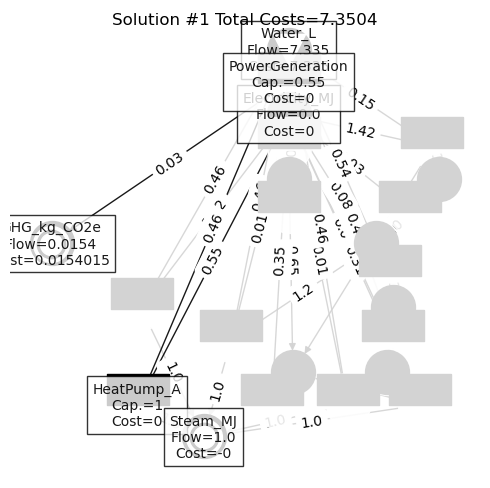

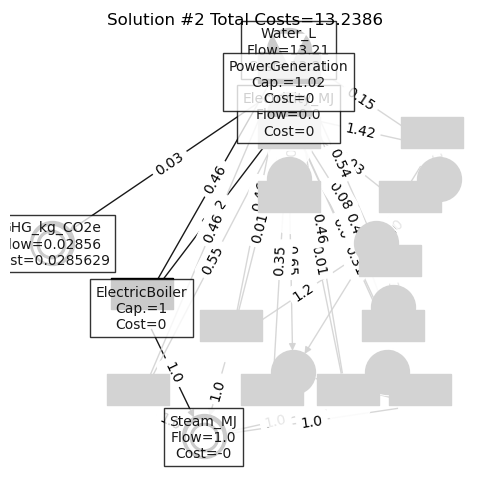

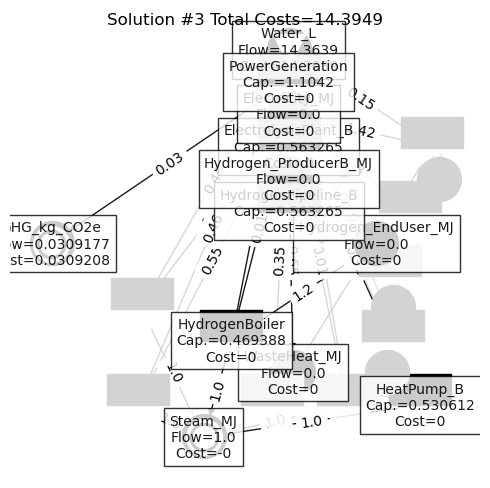

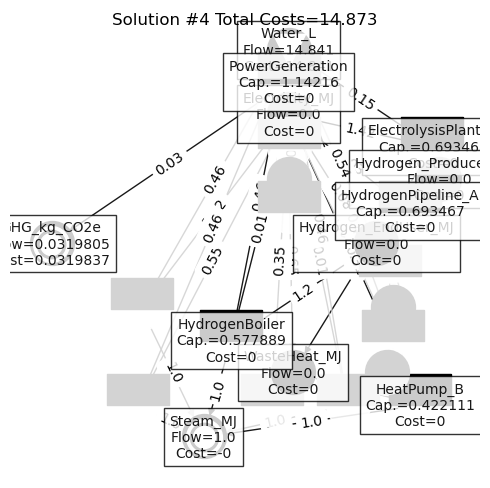

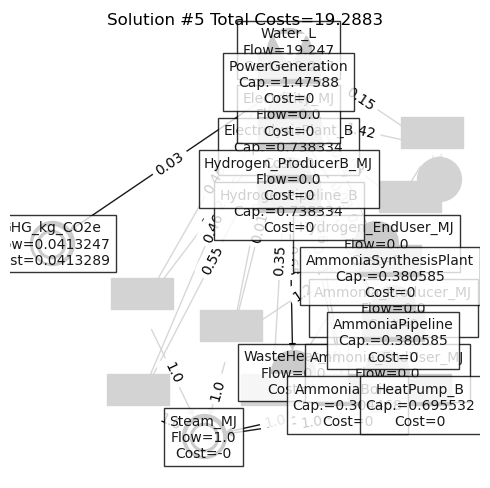

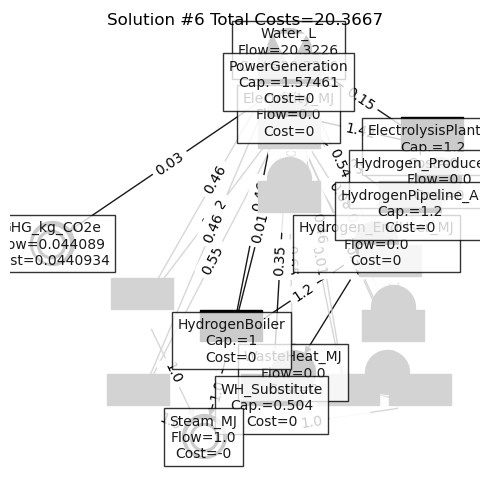

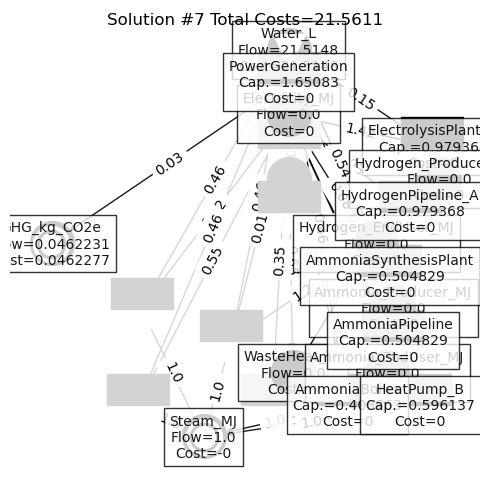

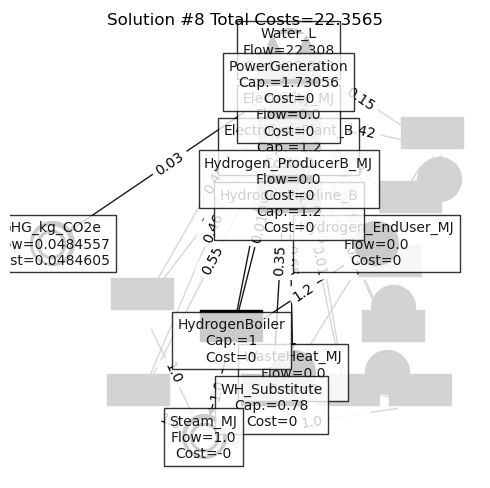

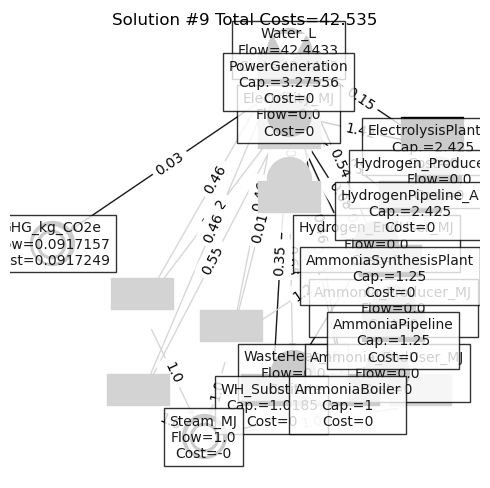

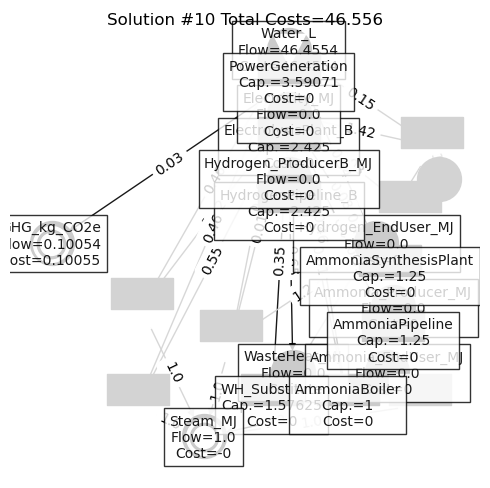

In [21]:
total_sol_num=P.get_sol_num()
for i in range(total_sol_num):
    fig,ax=plt.subplots(1,1,layout="tight")
    ax=P.plot_solution(sol_num=i,figsize=(5,5),node_size=1000,rescale=1,box=False, padding=0)
    plt.show()
